# PROBLEM STATEMENT

The increasing intention of Nigerian youths to emigrate poses significant challenges to the country's workforce, economic growth, and human capital development. Despite widespread discussions surrounding the Japa phenomenon, there is insufficient data-driven evidence regarding the key factors influencing emigration intentions. Furthermore, predictive models capable of identifying youths who are more likely to consider emigration remain limited. This project addresses that gap by treating emigration intention as a measurable, predictable outcome and asking: what combination of demographic, economic, and psychological factors best predicts whether a young Nigerian intends to emigrate?


# DATA PREPARATION

In [1]:
# IMPORT NECESSARY LIBRARIES
import pandas as pd
import numpy as np

In [2]:
# LOAD THE DATASET
df = pd.read_csv("Emigration_intent_responses.csv")

In [3]:
# INSPECT DATA
# view the first 5 rows
df.head()

,Timestamp,Age,Gender,State of Residence,Marital Status,Highest Educational Qualification,What is your field of study or area of specialisation?,Current Employment Status,Monthly Income,How satisfied are you with your current income?,...,How important are the following factors in influencing your intention to emigrate from Nigeria? [Security],How important are the following factors in influencing your intention to emigrate from Nigeria? [Healthcare],How important are the following factors in influencing your intention to emigrate from Nigeria? [Family Reunification],How important are the following factors in influencing your intention to emigrate from Nigeria? [Better Quality of Life],Which country/continent would be your preferred destination if you were to emigrate?,Have you seriously considered leaving Nigeria within the next five years?,How strong is your desire to emigrate?,"If given the opportunity today, would you relocate abroad?",How likely are you to actively pursue migration opportunities within the next two years?,"In your own words, what is the primary reason for your answer?"
0,6/24/2026 21:40:06,24–29 years,Female,Enugu,Single,Bachelor's Degree,Computer Science/ICT/Tech,Employed (Public sector/ Government),"₦50,000 – ₦100,000",1,...,Important,Important,Not important,Important,NaN,Yes,5,Yes,5,NaN
1,6/24/2026 22:19:46,24–29 years,Male,FCT Abuja,Single,Bachelor's Degree,Education,Self-employed/Entrepreneur,"₦100,001 – ₦200,000",1,...,Very important,Very important,Very important,Very important,Canada,Yes,5,Yes,5,Better life
2,6/24/2026 23:37:57,24–29 years,Male,Edo,Single,Bachelor's Degree,Engineering/Technology,Unemployed,No Income,1,...,Very important,Very important,Important,Very important,Canada,Yes,5,Yes,5,Studies and better opportunities
3,6/25/2026 6:12:31,24–29 years,Female,FCT Abuja,Single,Bachelor's Degree,Medicine/Health Sciences,Employed (Private sector),"₦100,001 – ₦200,000",3,...,Very important,Very important,Very important,Very important,Finland,No,3,Yes,3,I have no idea on how to pursue the career abr...
4,6/25/2026 7:35:47,30–35 years,Female,Anambra,Married,Bachelor's Degree,Business/Management Sciences,Employed (Private sector),"Below ₦50,000",1,...,Very important,Very important,Moderately important,Very important,Netherlands,Yes,5,Yes,3,Funds are my major factor for me


In [4]:
# view the shape
df.shape

(188, 36)

In [5]:
# Display column names
df.columns

Index(['Timestamp', 'Age', 'Gender', 'State of Residence', 'Marital Status',
       'Highest Educational Qualification',
       ' What is your field of study or area of specialisation?',
       'Current Employment Status', 'Monthly Income',
       'How satisfied are you with your current income?',
       'How satisfied are you with employment opportunities available in Nigeria?',
       'I believe I can achieve my career goals while living in Nigeria.',
       'How would you rate the security situation in Nigeria?',
       'How satisfied are you with the quality of public services in Nigeria (electricity, healthcare, roads, etc.)?',
       'How optimistic are you about Nigeria's future?',
       'Corruption significantly affects opportunities available to young people in Nigeria.',
       'I feel hopeful about achieving my personal goals in Nigeria.',
       'I am generally satisfied with my current quality of life in Nigeria.',
       'I believe my future prospects would be significan

In [6]:
# Shorten column names
df.columns = [
    'timestamp', 'age', 'gender', 'state', 'marital_status',
    'education', 'field_of_study', 'employment_status',
    'monthly_income', 'income_satisfaction',
    'employment_satisfaction', 'career_goals_nigeria',
    'security_rating', 'public_services', 'future_optimism',
    'corruption_effect', 'personal_goal_hope',
    'quality_of_life', 'better_future_abroad',
    'emotional_attachment', 'family_abroad', 'friends_abroad',
    'migration_application', 'factor_job', 'factor_income',
    'factor_education', 'factor_security',
    'factor_healthcare', 'factor_family',
    'factor_quality_life', 'preferred_destination',
    'considered_emigration', 'desire_to_emigrate',
    'relocate_today', 'migration_likelihood',
    'open_response'
]

In [7]:
# Get information about the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 188 entries, 0 to 187
Data columns (total 36 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   timestamp                188 non-null    object
 1   age                      188 non-null    object
 2   gender                   188 non-null    object
 3   state                    188 non-null    object
 4   marital_status           188 non-null    object
 5   education                188 non-null    object
 6   field_of_study           188 non-null    object
 7   employment_status        188 non-null    object
 8   monthly_income           188 non-null    object
 9   income_satisfaction      188 non-null    int64 
 10  employment_satisfaction  188 non-null    int64 
 11  career_goals_nigeria     188 non-null    int64 
 12  security_rating          188 non-null    int64 
 13  public_services          188 non-null    int64 
 14  future_optimism          188 non-null    i

In [8]:
# Summary statistics
df.describe()

,income_satisfaction,employment_satisfaction,career_goals_nigeria,security_rating,public_services,future_optimism,corruption_effect,personal_goal_hope,quality_of_life,better_future_abroad,emotional_attachment,desire_to_emigrate,migration_likelihood
count,188.000000,188.000000,188.000000,188.000000,188.000000,188.00000,188.000000,188.000000,188.000000,188.000000,188.000000,188.000000,188.000000
mean,2.042553,1.590426,2.803191,1.143617,1.473404,2.50000,4.122340,2.877660,1.627660,3.984043,2.505319,4.000000,3.797872
std,1.146162,0.995881,1.231750,0.445550,0.727118,1.20826,1.462885,1.210882,0.958877,1.234426,1.238843,1.287538,1.279871
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,1.000000,1.000000,2.000000,1.000000,1.000000,1.00000,4.000000,2.000000,1.000000,3.000000,1.000000,3.000000,3.000000
50%,2.000000,1.000000,3.000000,1.000000,1.000000,3.00000,5.000000,3.000000,1.000000,4.000000,2.000000,5.000000,4.000000
75%,3.000000,2.000000,3.000000,1.000000,2.000000,3.00000,5.000000,4.000000,2.000000,5.000000,3.000000,5.000000,5.000000
max,5.000000,5.000000,5.000000,4.000000,5.000000,5.00000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000


In [9]:
# Summary statistics for all columns including categorical values
df.describe(include = 'all')

,timestamp,age,gender,state,marital_status,education,field_of_study,employment_status,monthly_income,income_satisfaction,...,factor_security,factor_healthcare,factor_family,factor_quality_life,preferred_destination,considered_emigration,desire_to_emigrate,relocate_today,migration_likelihood,open_response
count,188,188,188,188,188,188,188,188,188,188.000000,...,188,188,188,188,160,188,188.000000,188,188.000000,146
unique,188,3,2,17,3,6,11,6,6,NaN,...,5,5,5,5,76,2,NaN,2,NaN,138
top,6/24/2026 21:40:06,24–29 years,Female,Enugu,Single,Bachelor's Degree,Education,Employed (Private sector),"₦50,000 – ₦100,000",NaN,...,Very important,Very important,Very important,Very important,Canada,Yes,NaN,Yes,NaN,Better life
freq,1,126,107,80,156,140,37,67,54,NaN,...,121,119,46,118,22,156,NaN,175,NaN,5
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.042553,...,NaN,NaN,NaN,NaN,NaN,NaN,4.000000,NaN,3.797872,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.146162,...,NaN,NaN,NaN,NaN,NaN,NaN,1.287538,NaN,1.279871,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,1.000000,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,3.000000,NaN,3.000000,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,5.000000,NaN,4.000000,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,5.000000,NaN,5.000000,NaN


In [10]:
# Check for missing values
df.isnull().sum()

timestamp                   0
age                         0
gender                      0
state                       0
marital_status              0
education                   0
field_of_study              0
employment_status           0
monthly_income              0
income_satisfaction         0
employment_satisfaction     0
career_goals_nigeria        0
security_rating             0
public_services             0
future_optimism             0
corruption_effect           0
personal_goal_hope          0
quality_of_life             0
better_future_abroad        0
emotional_attachment        0
family_abroad               0
friends_abroad              0
migration_application      90
factor_job                  0
factor_income               0
factor_education            0
factor_security             0
factor_healthcare           0
factor_family               0
factor_quality_life         0
preferred_destination      28
considered_emigration       0
desire_to_emigrate          0
relocate_t

In [11]:
# check for duplicate rows
df.duplicated().sum()

np.int64(0)

**Dataset Summary**

1. Number of responses: 188
   
2. Number of features: 36

3. Missing values: Present in only a few columns

4. Numerical columns: 13

5. Categorical columns: 23

6. Number of duplicate rows: 0

# DATA CLEANING

(a) Have you ever applied for any of the following? (migration_application)


This has 90 missing values.

This is expected because respondents who never applied left it blank.

In [12]:
# Replace missing values with "None" for this particular column
df['migration_application'] = (
    df['migration_application']
    .fillna('None')
)

(b) Preferred destination

28 missing values.

This is reasonable because some respondents may not want to emigrate or may want to emigrate but have no preferred location yet.

I won't fill missing values because i won't use this column to build the model.

(c) Open-ended question (Open response)

Has 42 missing values.

This is an optional text response.

I will not fill these missing values because I won't be using this column for building the machine learning model.

In [13]:
# Timestamp has no predictive value. Drop it
df.drop(columns=['timestamp'], inplace=True)

In [14]:
# check again for missing values
df.isnull().sum()

age                         0
gender                      0
state                       0
marital_status              0
education                   0
field_of_study              0
employment_status           0
monthly_income              0
income_satisfaction         0
employment_satisfaction     0
career_goals_nigeria        0
security_rating             0
public_services             0
future_optimism             0
corruption_effect           0
personal_goal_hope          0
quality_of_life             0
better_future_abroad        0
emotional_attachment        0
family_abroad               0
friends_abroad              0
migration_application       0
factor_job                  0
factor_income               0
factor_education            0
factor_security             0
factor_healthcare           0
factor_family               0
factor_quality_life         0
preferred_destination      28
considered_emigration       0
desire_to_emigrate          0
relocate_today              0
migration_

In [15]:
# Examine all categorical variables
for col in df.select_dtypes(include='object'):
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False))


age
age
24–29 years    126
30–35 years     48
18–23 years     14
Name: count, dtype: int64

gender
gender
Female    107
Male       81
Name: count, dtype: int64

state
state
Enugu        80
Lagos        34
Rivers       20
Anambra      14
FCT Abuja     9
Delta         7
Edo           5
Ogun          4
Kano          4
Imo           3
Akwa Ibom     2
Plateau       1
Kwara         1
Kaduna        1
Ebonyi        1
Kogi          1
Oyo           1
Name: count, dtype: int64

marital_status
marital_status
Single     156
Married     31
Widowed      1
Name: count, dtype: int64

education
education
Bachelor's Degree                140
Master's Degree                   18
Diploma/NCE                       14
Secondary School Certificate      11
Other (Specify): ____________      4
Doctorate Degree                   1
Name: count, dtype: int64

field_of_study
field_of_study
Education                        37
Medicine/Health Sciences         31
Engineering/Technology           28
Computer Science/I

# Exploratory Data Analysis

**Check for outliers**

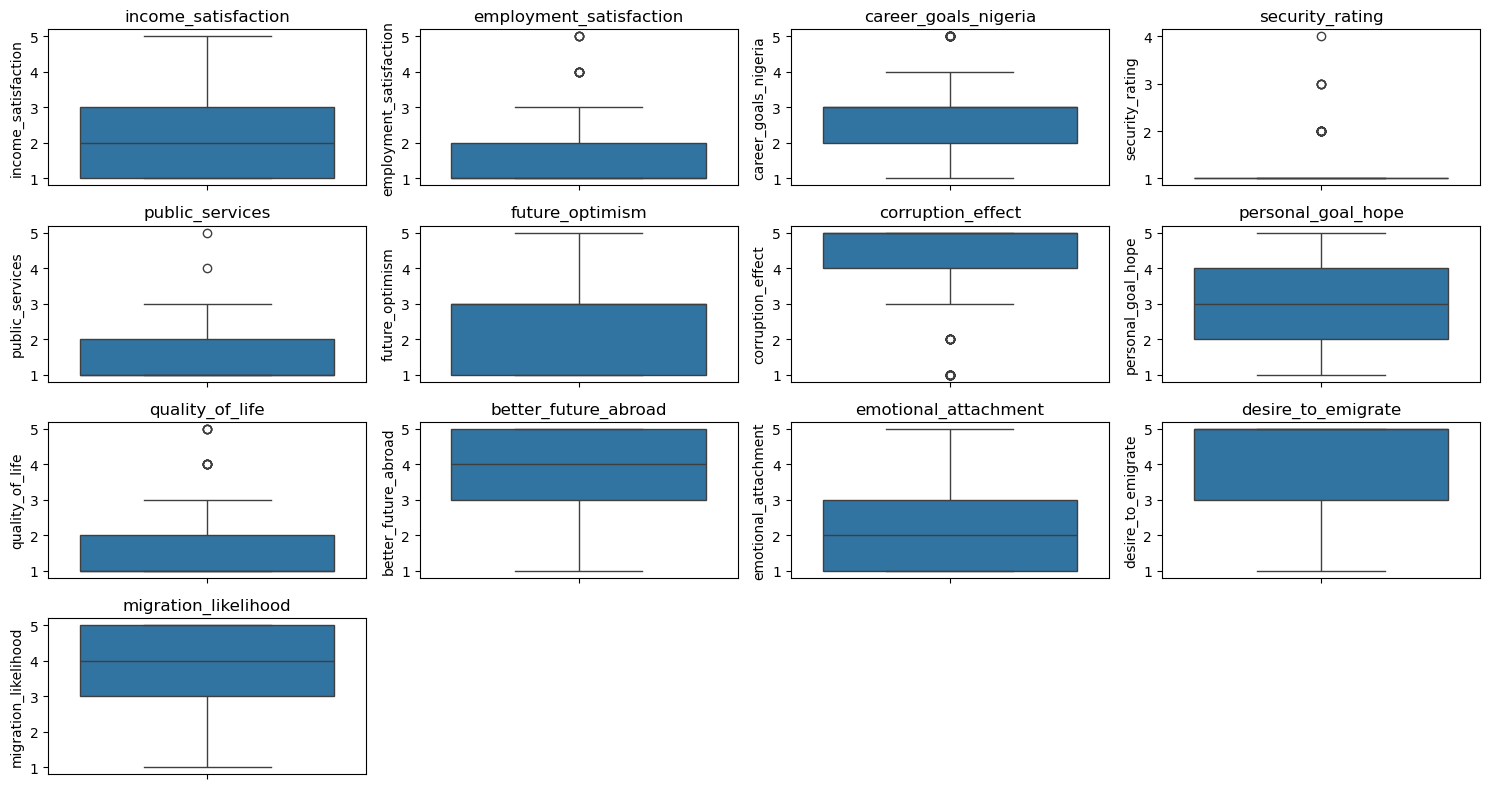

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns

plt.figure(figsize=(15,8))

for i, col in enumerate(numerical_cols, 1):
    plt.subplot(4,4,i)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

Most variables show a moderate spread with a few outliers. Since the data consists of Likert-scale responses (1–5), these outliers are likely genuine variations in respondents' opinions and will be retained for analysis.

**Note**

LIKERT SCALE DEFINITIONS


 Agreement Scale
 
 1 = Strongly Disagree
 2 = Disagree
 3 = Neutral
 4 = Agree
 5 = Strongly Agree

 Satisfaction Scale
 
 1 = Very Dissatisfied
 2 = Dissatisfied
 3 = Neutral
 4 = Satisfied
 5 = Very Satisfied

 Optimism Scale
 
 1 = Very Pessimistic
 2 = Pessimistic
 3 = Neutral
 4 = Optimistic
 5 = Very Optimistic

 Rating Scale (e.g., Security, Public Services)
 
 1 = Very Poor
 2 = Poor
 3 = Fair
 4 = Good
 5 = Very Good

 Importance Scale (Migration Factors)
 
 1 = Not Important
 2 = Slightly Important
 3 = Moderately Important
 4 = Important
 5 = Very Important


**Univariate Analysis**

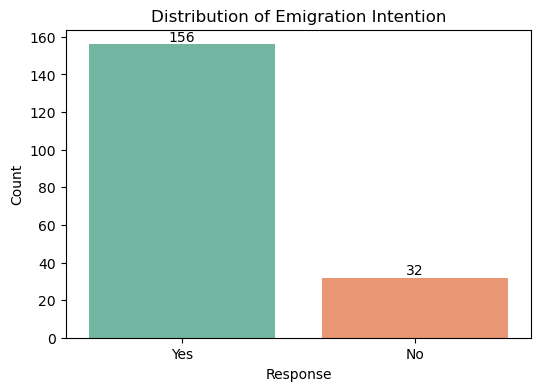

In [17]:
# DISTRIBUTION OF TARGET VARIABLE
plt.figure(figsize=(6,4))

ax = sns.countplot(
    x='considered_emigration',
    hue='considered_emigration',
    data=df,
    palette='Set2',
    legend=False
)

# Add count labels
for container in ax.containers:
    ax.bar_label(container)

plt.title('Distribution of Emigration Intention')
plt.xlabel('Response')
plt.ylabel('Count')

plt.show()

The distribution shows that the majority of respondents have seriously considered leaving Nigeria within the next five years, while only a few respondents have not. This suggests a high level of emigration intention among the surveyed population.



The target variable is imbalanced, with significantly more 'Yes' responses than 'No' responses. This class imbalance should be considered during model development, as it may affect the model's ability to accurately predict the minority class.

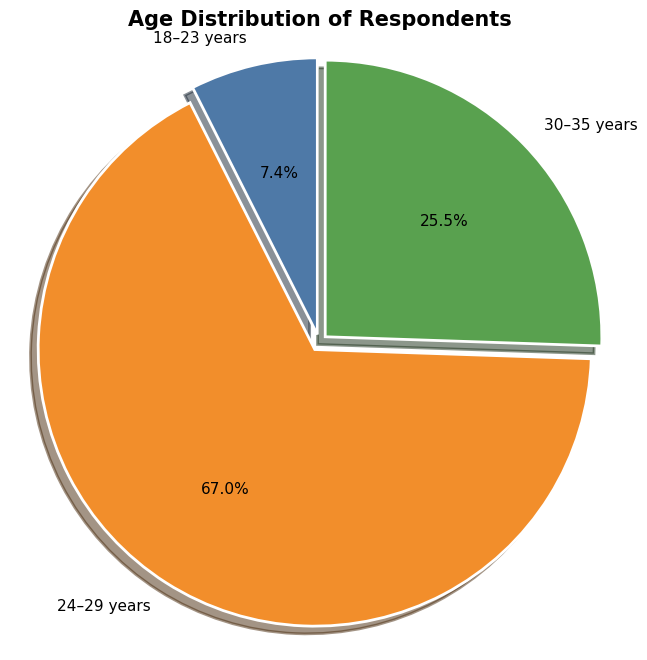

In [18]:
# Count respondents in each age group
age_counts = df['age'].value_counts().sort_index()

# Define colours
colors = ['#4E79A7', '#F28E2B', '#59A14F', '#E15759', '#76B7B2']

plt.figure(figsize=(8,8))

plt.pie(
    age_counts,
    labels=age_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=colors,
    explode=[0.03]*len(age_counts),   # Slightly separate slices
    shadow=True,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2},
    textprops={'fontsize': 11}
)

plt.title('Age Distribution of Respondents', fontsize=15, fontweight='bold')
plt.axis('equal')   # Makes the pie chart circular

plt.show()

The age distribution indicates that most respondents are between 24–29 years old, followed by those aged 30–35 years, while the 18–23 years age group has the fewest respondents. This suggests that the survey primarily captured the views of young adults in their mid-to-late twenties.

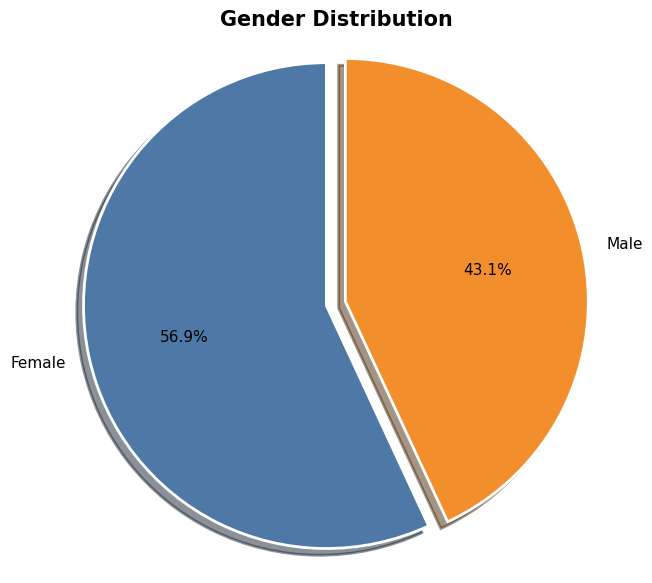

In [19]:
# Count respondents by gender
gender_counts = df['gender'].value_counts()

# Define colours
colors = ['#4E79A7', '#F28E2B', '#59A14F']

plt.figure(figsize=(7,7))

plt.pie(
    gender_counts,
    labels=gender_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=colors,
    explode=[0.04]*len(gender_counts),
    shadow=True,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2},
    textprops={'fontsize': 11}
)

plt.title('Gender Distribution', fontsize=15, fontweight='bold')
plt.axis('equal')  # Makes the pie chart circular

plt.show()

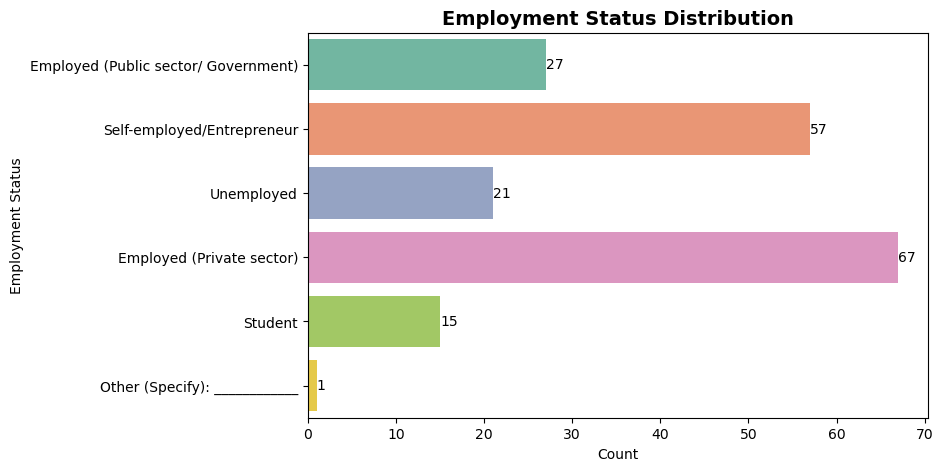

In [20]:
# Employment status distribution
plt.figure(figsize=(8,5))

ax = sns.countplot(
    y='employment_status',
    hue='employment_status',
    data=df,
    palette='Set2',
    legend=False
)

# Add count labels
for container in ax.containers:
    ax.bar_label(container)

plt.title('Employment Status Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Count')
plt.ylabel('Employment Status')

plt.show()

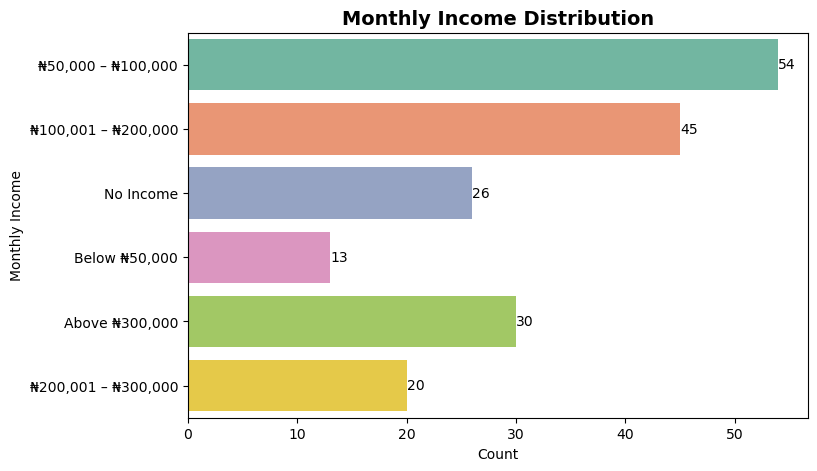

In [21]:
# Monthly income distribution
plt.figure(figsize=(8,5))

ax = sns.countplot(
    y='monthly_income',
    data=df,
    hue='monthly_income',
    palette='Set2',
    legend=False
)

# Add count labels
for container in ax.containers:
    ax.bar_label(container)

plt.title('Monthly Income Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Count')
plt.ylabel('Monthly Income')

plt.show()

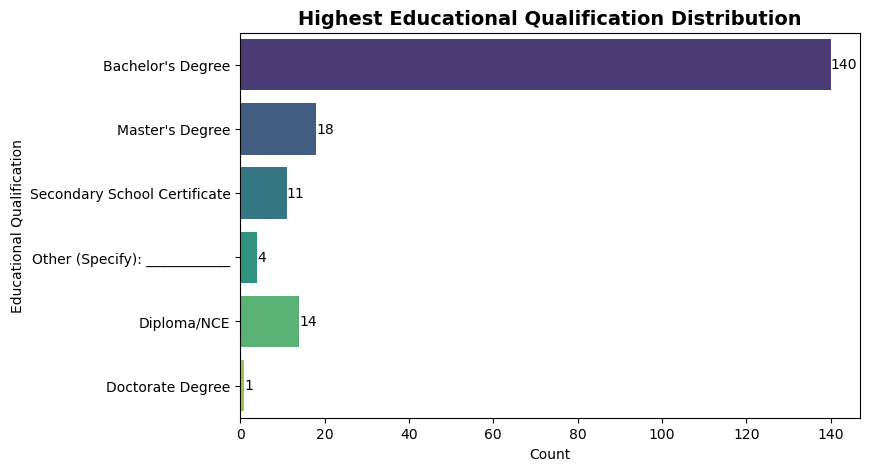

In [22]:
# Educational qualification distribution
plt.figure(figsize=(8,5))

ax = sns.countplot(
    y='education',
    data=df,
    hue='education',
    palette='viridis',
    legend=False
)

# Add count labels
for container in ax.containers:
    ax.bar_label(container)

plt.title('Highest Educational Qualification Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Count')
plt.ylabel('Educational Qualification')

plt.show()

The distribution of respondents by educational qualification shows that the majority possess tertiary-level qualifications, indicating that the survey predominantly captured educated Nigerian youths.

**Bivariate Analysis**

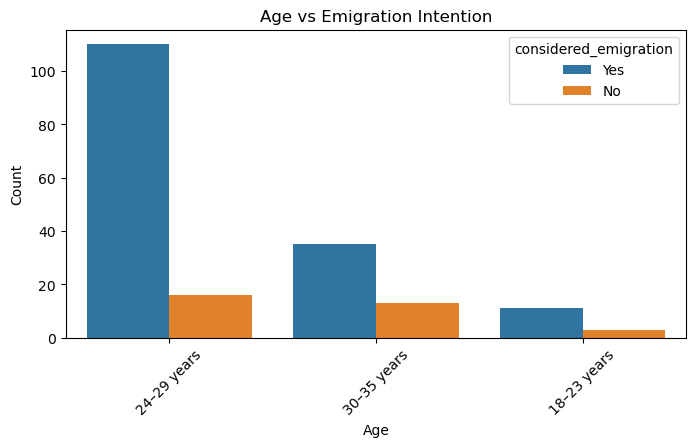

In [23]:
# Age vs Emigration intention
plt.figure(figsize=(8,4))
sns.countplot(x='age', hue='considered_emigration', data=df)

plt.title('Age vs Emigration Intention')
plt.xlabel('Age')
plt.ylabel('Count')
plt.xticks(rotation=45)

plt.show()

The chart shows that respondents aged 24–29 years recorded the highest number of individuals who have seriously considered leaving Nigeria within the next five years. Across all age groups, the number of respondents intending to emigrate exceeds those with no intention, suggesting that emigration intention is more common among younger respondents.

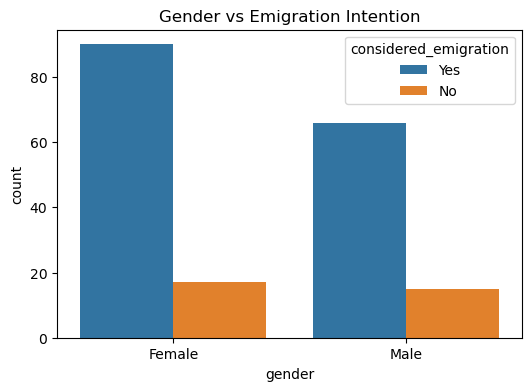

In [24]:
# Gender vs Emigration intention

plt.figure(figsize=(6,4))
sns.countplot(x='gender',
              hue='considered_emigration',
              data=df)

plt.title('Gender vs Emigration Intention')

plt.show()

The chart shows that both male and female respondents reported a higher intention to emigrate than to remain in Nigeria. Female respondents recorded a slightly higher number of individuals intending to emigrate compared to males, although the difference is relatively small.

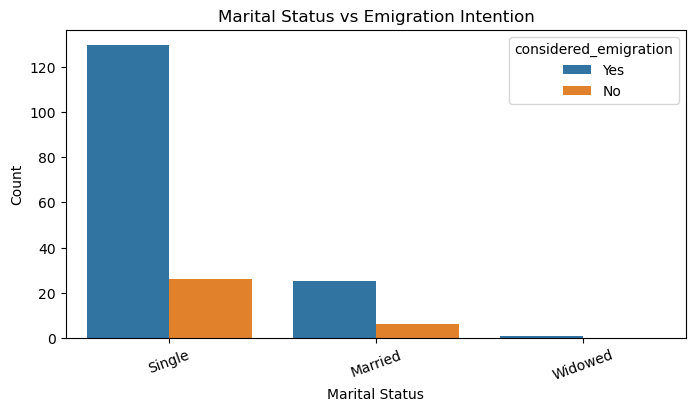

In [25]:
# Marital status vs Emigration intention
plt.figure(figsize=(8,4))
sns.countplot(x='marital_status', hue='considered_emigration', data=df)

plt.title('Marital Status vs Emigration Intention')
plt.xlabel('Marital Status')
plt.ylabel('Count')
plt.xticks(rotation=20)

plt.show()

The chart shows that single respondents recorded the highest number of individuals who have seriously considered leaving Nigeria within the next five years. Married respondents also exhibited a higher intention to emigrate than to remain, while very few widowed respondents were represented in the survey. Overall, the majority of respondents across all marital status categories expressed an intention to emigrate.

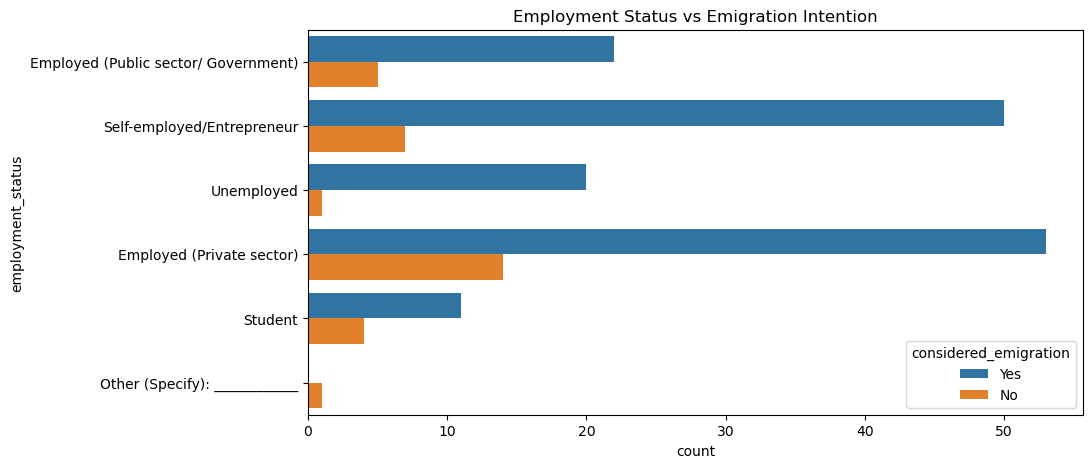

In [26]:
# Employment status vs Target

plt.figure(figsize=(10,5))
sns.countplot(y='employment_status',
              hue='considered_emigration',
              data=df)

plt.title('Employment Status vs Emigration Intention')

plt.show()

The chart shows that respondents employed in the private sector and those who are self-employed recorded the highest numbers of individuals who have seriously considered leaving Nigeria within the next five years. Across nearly all employment categories, respondents intending to emigrate outnumbered those with no intention to leave, suggesting that emigration interest is widespread regardless of employment status.

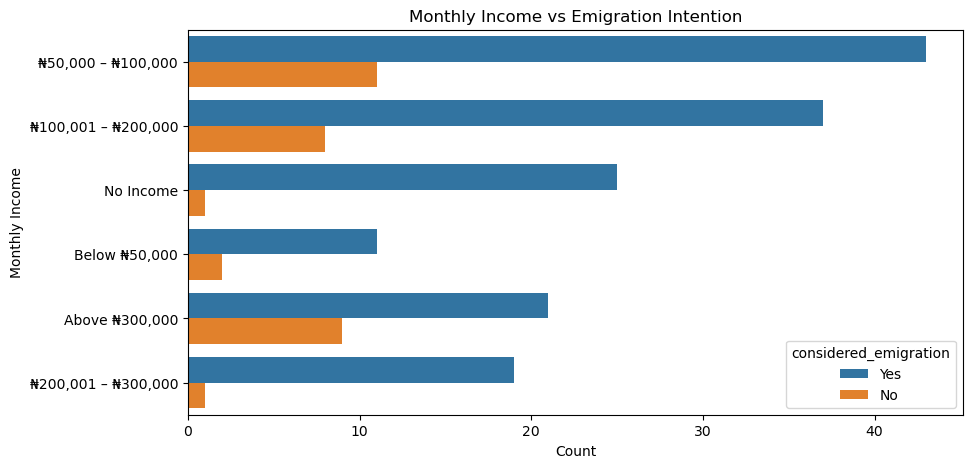

In [27]:
# Monthly income vs Emigration status
plt.figure(figsize=(10,5))
sns.countplot(y='monthly_income', hue='considered_emigration', data=df)

plt.title('Monthly Income vs Emigration Intention')
plt.xlabel('Count')
plt.ylabel('Monthly Income')

plt.show()

Across all monthly income categories, respondents intending to emigrate outnumbered those with no intention to leave Nigeria. The highest counts were recorded among respondents earning ₦50,000–₦100,000 and ₦100,001–₦200,000 per month.

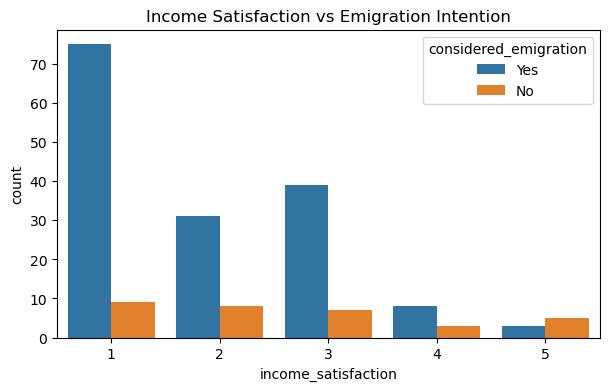

In [28]:
# Income satisfaction vs Target

plt.figure(figsize=(7,4))
sns.countplot(x='income_satisfaction',
              hue='considered_emigration',
              data=df)

plt.title('Income Satisfaction vs Emigration Intention')

plt.show()

The chart indicates that respondents who reported lower levels of satisfaction with their current income (particularly ratings 1 and 2) recorded the highest numbers of individuals who have seriously considered leaving Nigeria within the next five years. As income satisfaction increases, the number of respondents expressing an intention to emigrate generally declines, suggesting that lower income satisfaction may be associated with stronger emigration intentions.

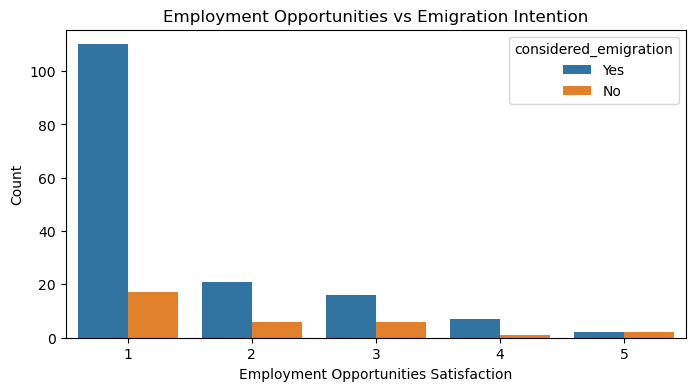

In [29]:
# Employment oppourtunity vs Emigration status
plt.figure(figsize=(8,4))
sns.countplot(
    x='employment_satisfaction',
    hue='considered_emigration',
    data=df
)

plt.title('Employment Opportunities vs Emigration Intention')
plt.xlabel('Employment Opportunities Satisfaction')
plt.ylabel('Count')

plt.show()

The chart shows that respondents who expressed the lowest level of satisfaction with employment opportunities in Nigeria (rating 1) recorded the highest number of individuals who have seriously considered leaving Nigeria within the next five years. As satisfaction with employment opportunities increases, the number of respondents intending to emigrate generally decreases, suggesting that dissatisfaction with employment opportunities may be associated with stronger emigration intentions

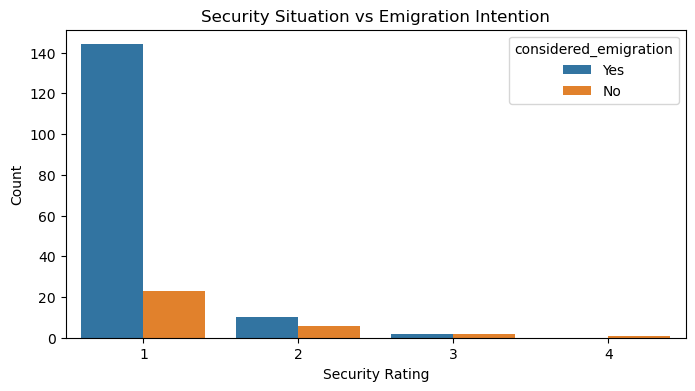

In [30]:
# Security situation  vs Emigration intention
plt.figure(figsize=(8,4))
sns.countplot(
    x='security_rating',
    hue='considered_emigration',
    data=df
)

plt.title('Security Situation vs Emigration Intention')
plt.xlabel('Security Rating')
plt.ylabel('Count')

plt.show()

Respondents who rated Nigeria's security situation poorly recorded the highest counts of individuals intending to emigrate. Overall, emigration intention appears to decline as perceptions of the country's security improve.

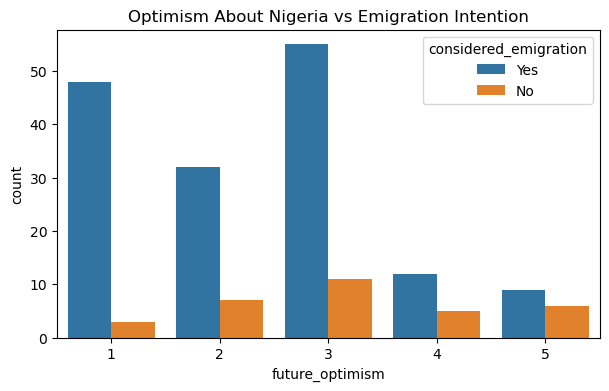

In [31]:
# Optimism about nigeria vs Target
plt.figure(figsize=(7,4))
sns.countplot(x="future_optimism",
              hue='considered_emigration',
              data=df)

plt.title('Optimism About Nigeria vs Emigration Intention')

plt.show()

The chart shows that respondents with lower levels of optimism about Nigeria's future (particularly ratings 1, 2, and 3) recorded the highest numbers of individuals who have seriously considered leaving Nigeria within the next five years. Although respondents across all optimism levels expressed an intention to emigrate, the number generally decreases as optimism increases, suggesting that lower optimism about the country's future may be associated with stronger emigration intentions.

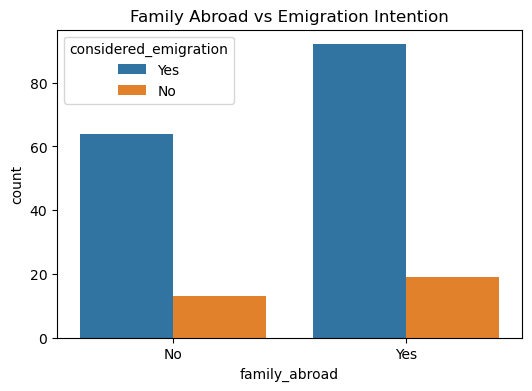

In [32]:
# Family abroad vs Target
plt.figure(figsize=(6,4))
sns.countplot(x='family_abroad',
              hue='considered_emigration',
              data=df)

plt.title('Family Abroad vs Emigration Intention')

plt.show()

Emigration intention was high among both groups, but respondents with close family members living abroad recorded a slightly higher count of individuals intending to emigrate.

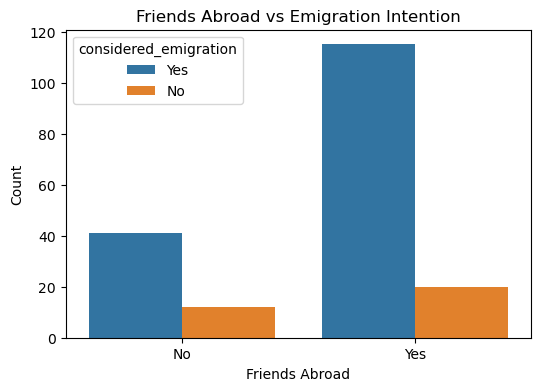

In [33]:
# Friends abroad vs Emigration Intention
plt.figure(figsize=(6,4))
sns.countplot(
    x='friends_abroad',
    hue='considered_emigration',
    data=df
)

plt.title('Friends Abroad vs Emigration Intention')
plt.xlabel('Friends Abroad')
plt.ylabel('Count')

plt.show()

Emigration intention was high among both groups, but respondents with close friends living abroad recorded a higher count of individuals intending to emigrate.

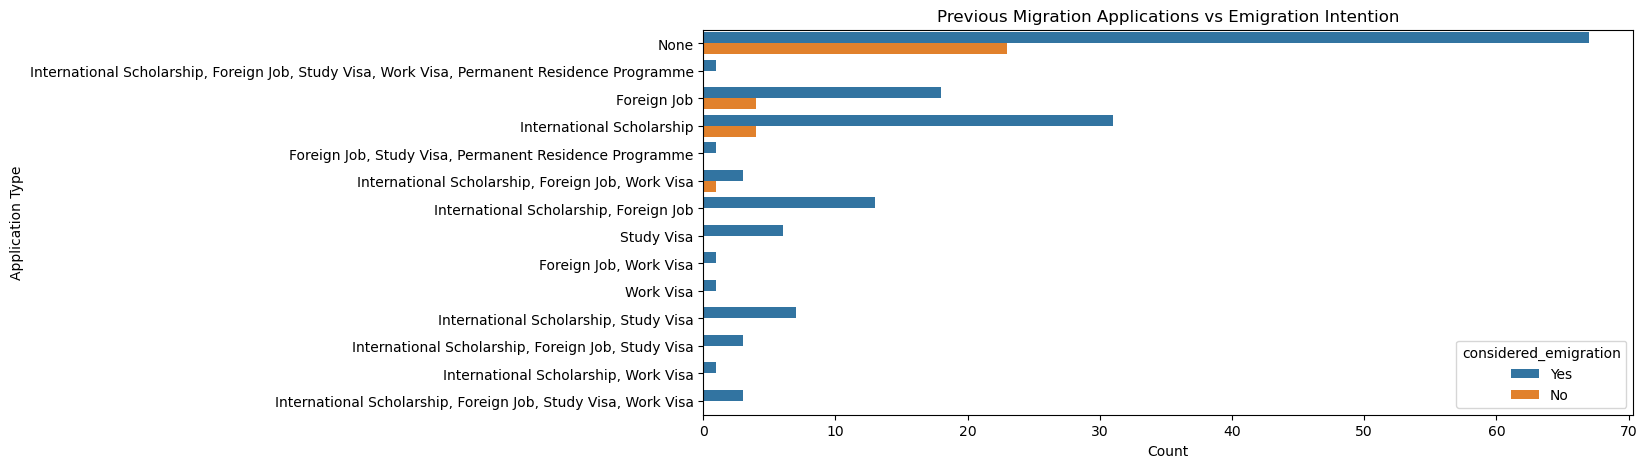

In [34]:
# Previous Migration Applications vs Emigration Intention
plt.figure(figsize=(12,5))
sns.countplot(
    y='migration_application',
    hue='considered_emigration',
    data=df
)

plt.title('Previous Migration Applications vs Emigration Intention')
plt.xlabel('Count')
plt.ylabel('Application Type')

plt.show()

Most respondents who had never submitted a migration application still expressed an intention to emigrate. Among previous applicants, international scholarships, study visas, and foreign jobs were the most common pathways, with emigration intention exceeding non-emigration across most application types.

**Multivariate Analysis**

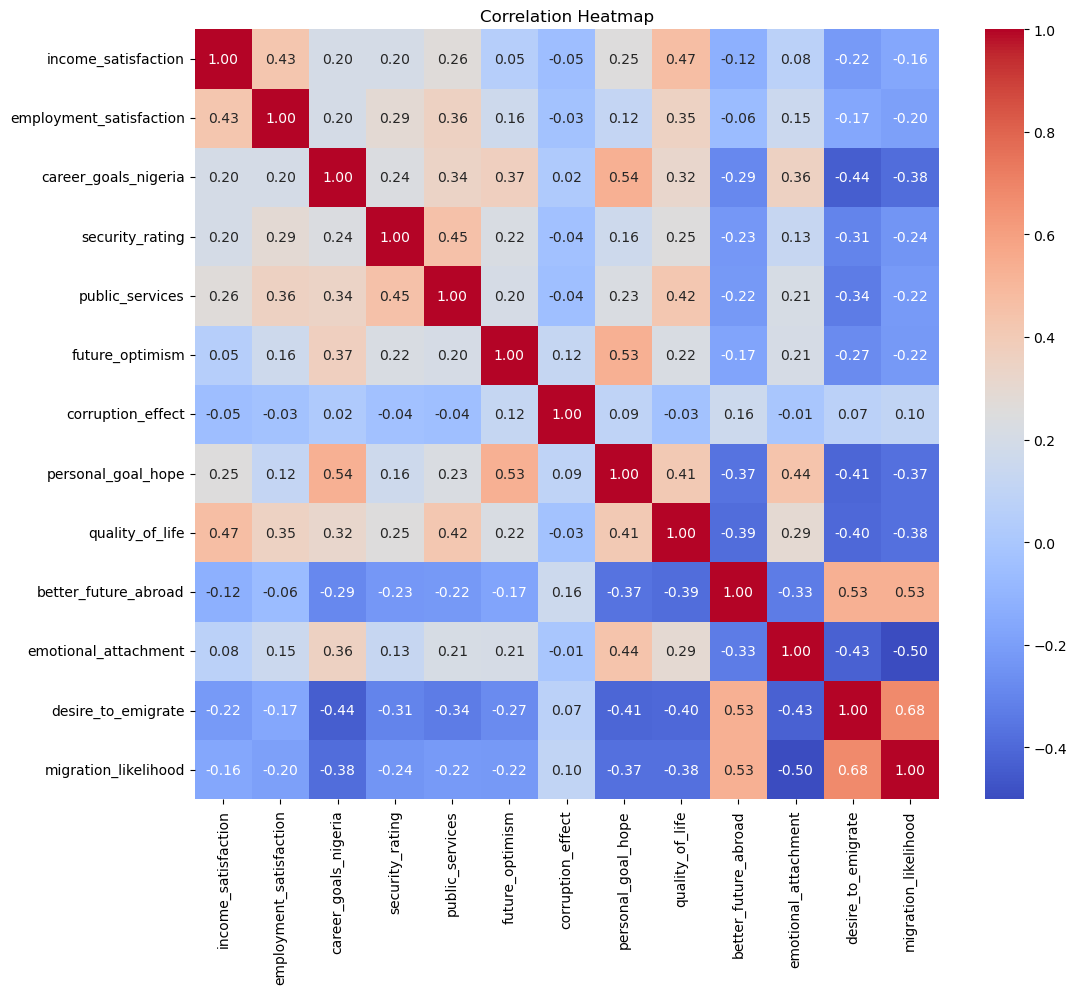

In [35]:
# Correlation Heatmap
numerical = df.select_dtypes(include=['int64','float64'])

plt.figure(figsize=(12,10))
sns.heatmap(numerical.corr(),
            annot=True,
            cmap='coolwarm',
            fmt='.2f')

plt.title('Correlation Heatmap')

plt.show()

**Average importance of the migration factors**

In [36]:
# Define the migration factor columns
migration_factors = [
    'factor_job',
    'factor_income',
    'factor_education',
    'factor_security',
    'factor_healthcare',
    'factor_family',
    'factor_quality_life'
]

In [37]:
# check the response form
for col in migration_factors:
    print(col)
    print(df[col].unique())
    print()

factor_job
['Very important' 'Important' 'Moderately important' 'Slightly important'
 'Not important']

factor_income
['Very important' 'Not important' 'Moderately important'
 'Slightly important' 'Important']

factor_education
['Important' 'Very important' 'Moderately important' 'Slightly important'
 'Not important']

factor_security
['Important' 'Very important' 'Moderately important' 'Slightly important'
 'Not important']

factor_healthcare
['Important' 'Very important' 'Moderately important' 'Not important'
 'Slightly important']

factor_family
['Not important' 'Very important' 'Important' 'Moderately important'
 'Slightly important']

factor_quality_life
['Important' 'Very important' 'Moderately important' 'Slightly important'
 'Not important']



In [38]:
# Convert text to numbers
importance_map = {
    'Not important': 1,
    'Slightly important': 2,
    'Moderately important': 3,
    'Important': 4,
    'Very important': 5
}

for col in migration_factors:
    df[col] = df[col].map(importance_map)

In [39]:
# check
for col in migration_factors:
    print(col)
    print(df[col].unique())
    print()

factor_job
[5 4 3 2 1]

factor_income
[5 1 3 2 4]

factor_education
[4 5 3 2 1]

factor_security
[4 5 3 2 1]

factor_healthcare
[4 5 3 1 2]

factor_family
[1 5 4 3 2]

factor_quality_life
[4 5 3 2 1]



In [40]:
# Calculate the average rating
average_scores = df[migration_factors].mean()

In [41]:
# Sort the factors
average_scores = average_scores.sort_values(ascending=False)

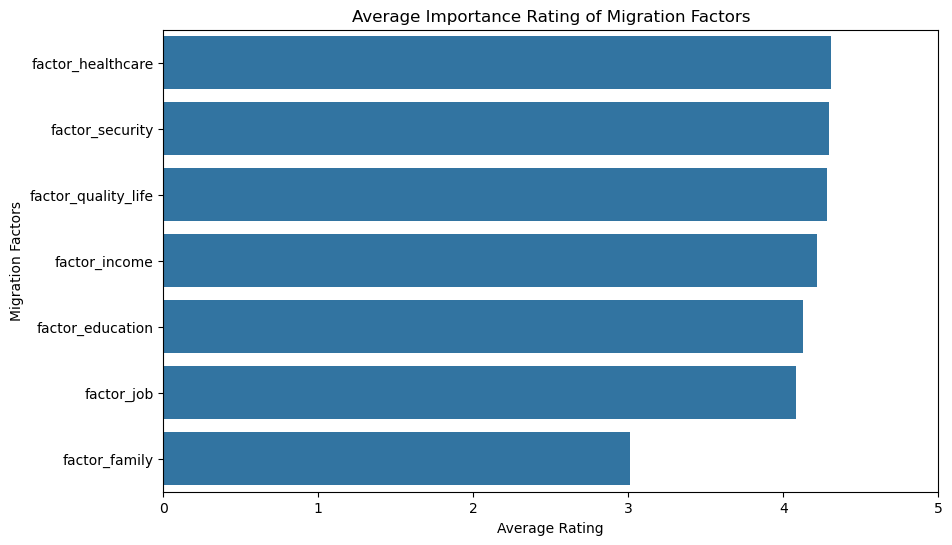

In [42]:
# Create the bar chart
plt.figure(figsize=(10,6))

sns.barplot(
    x=average_scores.values,
    y=average_scores.index
)

plt.title('Average Importance Rating of Migration Factors')

plt.xlabel('Average Rating')

plt.ylabel('Migration Factors')

plt.xlim(0,5)

plt.show()

The chart shows that all listed migration factors received relatively high average importance ratings from respondents. Healthcare, security, better quality of life, and higher income emerged as the highest-rated factors influencing migration decisions, while family reunification received the lowest average rating. This suggests that economic, social, and quality-of-life considerations are the primary drivers of emigration intentions among respondents.

In [43]:
# display ranking table
average_scores.to_frame(name='Average Rating')

,Average Rating
factor_healthcare,4.308511
factor_security,4.292553
factor_quality_life,4.281915
factor_income,4.218085
factor_education,4.127660
factor_job,4.079787
factor_family,3.010638


**Qualitative Exploratory Analysis**

In [44]:
# CHECK RESPONSES
text_col = "open_response"

df[text_col].value_counts().head(20)

open_response
Better life                                                                                                                                                                                                                                                                                                                                                                                                              5
Better opportunities                                                                                                                                                                                                                                                                                                                                                                                                     3
Better life                                                                                                                                                         

In [45]:
# CLEAN THE TEXT
import re

df["clean_text"] = (
    df["open_response"]
    .fillna("")
    .str.lower()
    .apply(lambda x: re.sub(r"[^a-zA-Z\s]", "", x))
)

In [46]:
# FIND THE MOST COMMON WORDS
from collections import Counter

words = " ".join(df["clean_text"]).split()

common_words = Counter(words).most_common(20)

print(common_words)

[('better', 80), ('i', 70), ('and', 66), ('to', 63), ('a', 62), ('life', 52), ('the', 47), ('for', 44), ('of', 42), ('in', 42), ('is', 35), ('my', 34), ('nigeria', 32), ('opportunities', 27), ('country', 21), ('want', 19), ('be', 17), ('me', 16), ('quality', 16), ('it', 16)]


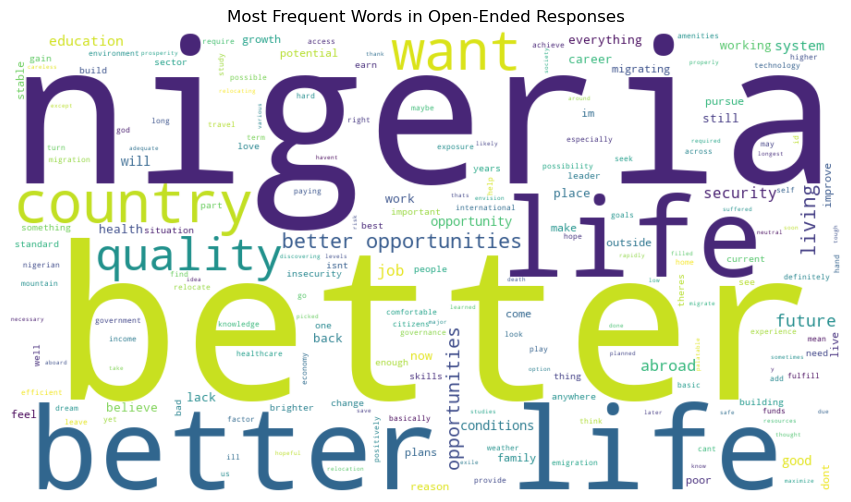

In [47]:
# CREATE A WORD CLOUD
from wordcloud import WordCloud
import matplotlib.pyplot as plt

text = " ".join(df["clean_text"])

wordcloud = WordCloud(
    width=900,
    height=500,
    background_color="white"
).generate(text)

plt.figure(figsize=(12,6))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Most Frequent Words in Open-Ended Responses")
plt.show()

In [48]:
# REMOVE MEANINGLESS WORDS
from wordcloud import STOPWORDS

stopwords = STOPWORDS.union({
    "nigeria",
    "people",
    "country",
    "would",
    "one",
    "also",
    "said",
    "like"
})

wordcloud = WordCloud(
    stopwords=stopwords,
    background_color="white"
).generate(text)

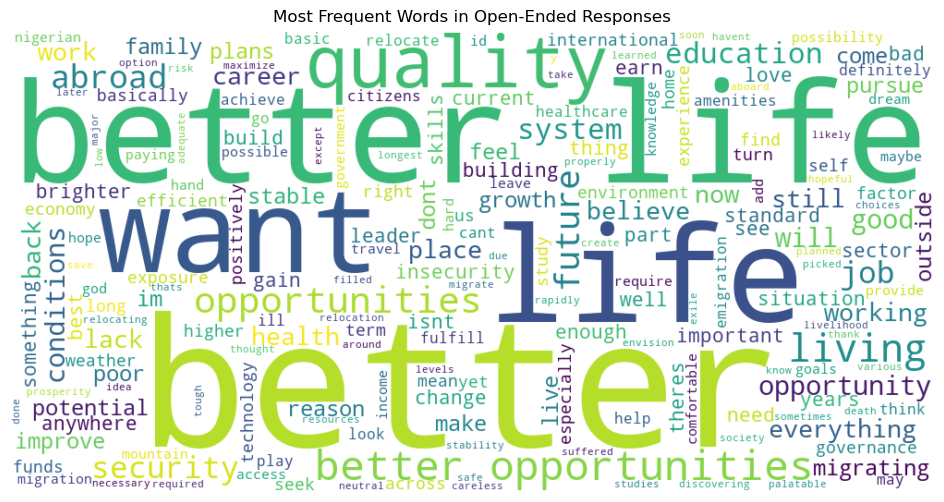

In [49]:
# Generate word cloud
wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color="white",
    stopwords=stopwords
).generate(text)

# Display
plt.figure(figsize=(12,6))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Most Frequent Words in Open-Ended Responses")
plt.show()

The word cloud highlights the most frequently used words in respondents' open-ended responses. Terms such as 'better', 'life', 'quality', 'opportunities', 'security', 'education', and 'abroad' appear most prominently, suggesting that respondents commonly associate emigration with improved living conditions, better career opportunities, enhanced security, and access to quality education.

In [50]:
from collections import Counter

words = [word for word in text.split() if word not in stopwords]

common_words = Counter(words).most_common(20)

common_words

[('better', 80),
 ('life', 52),
 ('opportunities', 27),
 ('want', 19),
 ('quality', 16),
 ('living', 13),
 ('future', 10),
 ('abroad', 9),
 ('security', 8),
 ('job', 7),
 ('education', 7),
 ('will', 6),
 ('system', 6),
 ('opportunity', 6),
 ('conditions', 6),
 ('good', 6),
 ('career', 5),
 ('lack', 5),
 ('believe', 5),
 ('place', 5)]

C:\Users\CHINECHEREM\AppData\Local\Temp\ipykernel_11192\824549104.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=word_df, x="Frequency", y="Word", palette="viridis")


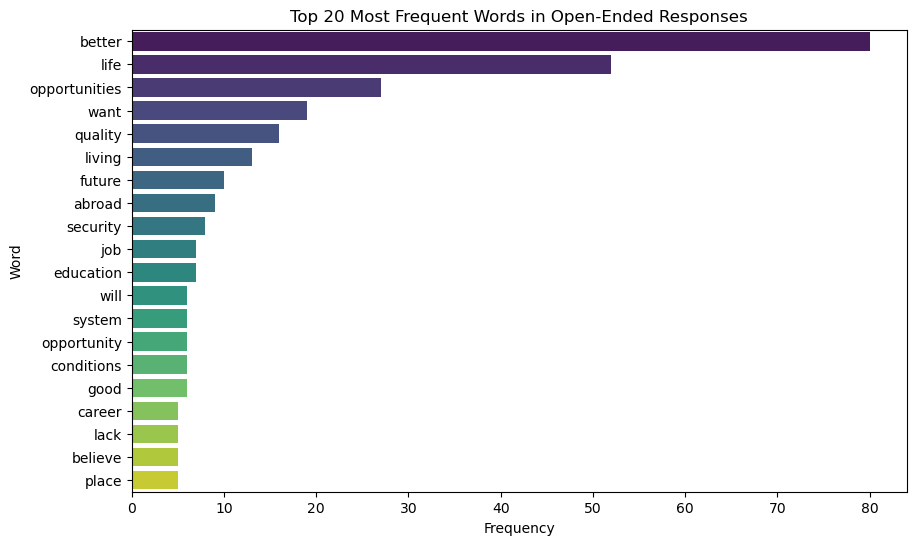

In [51]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

word_df = pd.DataFrame(common_words, columns=["Word", "Frequency"])

plt.figure(figsize=(10,6))
sns.barplot(data=word_df, x="Frequency", y="Word", palette="viridis")

plt.title("Top 20 Most Frequent Words in Open-Ended Responses")
plt.xlabel("Frequency")
plt.ylabel("Word")

plt.show()

The word cloud and frequency analysis show that respondents frequently mentioned terms related to employment, economic conditions, education, opportunities, and security. This suggests that these issues are among the primary factors influencing emigration intentions.

# Data Preprocessing

In [52]:
# Make a copy of the data set
df_ml = df.copy()

In [53]:
# Drop unnecessary columns
columns_to_drop = [
    'open_response',
    'preferred_destination',
    'desire_to_emigrate',
    'relocate_today',
    'migration_likelihood',
    'state'
]

df_ml.drop(columns=columns_to_drop, inplace=True)

In [54]:
df_ml.shape

(188, 30)

In [55]:
df_ml.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 188 entries, 0 to 187
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   age                      188 non-null    object
 1   gender                   188 non-null    object
 2   marital_status           188 non-null    object
 3   education                188 non-null    object
 4   field_of_study           188 non-null    object
 5   employment_status        188 non-null    object
 6   monthly_income           188 non-null    object
 7   income_satisfaction      188 non-null    int64 
 8   employment_satisfaction  188 non-null    int64 
 9   career_goals_nigeria     188 non-null    int64 
 10  security_rating          188 non-null    int64 
 11  public_services          188 non-null    int64 
 12  future_optimism          188 non-null    int64 
 13  corruption_effect        188 non-null    int64 
 14  personal_goal_hope       188 non-null    i

In [56]:
# Remove clean_text column
df_ml.drop(columns=['clean_text'], inplace=True)

In [57]:
# check
df_ml.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 188 entries, 0 to 187
Data columns (total 29 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   age                      188 non-null    object
 1   gender                   188 non-null    object
 2   marital_status           188 non-null    object
 3   education                188 non-null    object
 4   field_of_study           188 non-null    object
 5   employment_status        188 non-null    object
 6   monthly_income           188 non-null    object
 7   income_satisfaction      188 non-null    int64 
 8   employment_satisfaction  188 non-null    int64 
 9   career_goals_nigeria     188 non-null    int64 
 10  security_rating          188 non-null    int64 
 11  public_services          188 non-null    int64 
 12  future_optimism          188 non-null    int64 
 13  corruption_effect        188 non-null    int64 
 14  personal_goal_hope       188 non-null    i

# Seperate features and target

In [58]:
X = df_ml.drop('considered_emigration', axis=1)

y = df_ml['considered_emigration']

In [59]:
#check
y

0      Yes
1      Yes
2      Yes
3       No
4      Yes
      ... 
183    Yes
184    Yes
185    Yes
186     No
187    Yes
Name: considered_emigration, Length: 188, dtype: object

# Train test split

In [60]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

**Label Encoding**

In [61]:
label_map = {
    "Male": 0,
    "Female": 1,
    "No": 0,
    "Yes": 1
}

label_columns = [
    "gender",
    "family_abroad",
    "friends_abroad"
]

for col in label_columns:
    X_train[col] = X_train[col].map(label_map)
    X_test[col] = X_test[col].map(label_map)

**Ordinal Encoding**

In [62]:
# Age
age_map = {
    "18–23 years": 1,
    "24–29 years": 2,
    "30–35 years": 3
}

X_train["age"] = X_train["age"].map(age_map)
X_test["age"] = X_test["age"].map(age_map)

In [63]:
# Educational Qualification
education_map = {
    "Secondary School Certificate": 1,
    "Diploma/NCE": 2,
    "Bachelor's Degree": 3,
    "Master's Degree": 4,
    "Doctorate Degree": 5,
    "Other (Specify): ____________": 0
}

X_train["education"] = (
    X_train["education"].map(education_map)
)

X_test["education"] = (
    X_test["education"].map(education_map)
)

In [64]:
# Monthly Income
income_map = {
    "No Income": 0,
    "Below ₦50,000": 1,
    "₦50,000 – ₦100,000": 2,
    "₦100,001 – ₦200,000": 3,
    "₦200,001 – ₦300,000": 4,
    "Above ₦300,000": 5
}

X_train["monthly_income"] = X_train["monthly_income"].map(income_map)
X_test["monthly_income"] = X_test["monthly_income"].map(income_map)

**One Hot Encoding**

In [65]:
nominal_columns = [
    "marital_status",
    "field_of_study",
    "employment_status"
]

X_train = pd.get_dummies(
    X_train,
    columns=nominal_columns,
    drop_first=True,
    dtype=int
)

X_test = pd.get_dummies(
    X_test,
    columns=nominal_columns,
    drop_first=True,
    dtype=int
)

In [66]:
# Align the columns: Because some categories may appear only in the training set or only in the test set, align them afterwards
X_train, X_test = X_train.align(
    X_test,
    join="left",
    axis=1,
    fill_value=0
)

**Multi-label Encoding**

In [67]:
from sklearn.preprocessing import MultiLabelBinarizer

applications_train = (
    X_train["migration_application"]
    .fillna("None")
    .str.split(", ")
)

applications_test = (
    X_test["migration_application"]
    .fillna("None")
    .str.split(", ")
)

mlb = MultiLabelBinarizer()

train_applications = pd.DataFrame(
    mlb.fit_transform(applications_train),
    columns=mlb.classes_,
    index=X_train.index
)

test_applications = pd.DataFrame(
    mlb.transform(applications_test),
    columns=mlb.classes_,
    index=X_test.index
)

X_train = X_train.drop(
    columns=["migration_application"]
)

X_test = X_test.drop(
    columns=["migration_application"]
)

X_train = pd.concat([X_train, train_applications], axis=1)
X_test = pd.concat([X_test, test_applications], axis=1)

C:\Users\CHINECHEREM\Apps\Lib\site-packages\sklearn\preprocessing\_label.py:909: UserWarning: unknown class(es) ['Permanent Residence Programme'] will be ignored
  warnings.warn(


In [68]:
# check
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 150 entries, 163 to 50
Data columns (total 44 columns):
 #   Column                                                  Non-Null Count  Dtype
---  ------                                                  --------------  -----
 0   age                                                     150 non-null    int64
 1   gender                                                  150 non-null    int64
 2   education                                               150 non-null    int64
 3   monthly_income                                          150 non-null    int64
 4   income_satisfaction                                     150 non-null    int64
 5   employment_satisfaction                                 150 non-null    int64
 6   career_goals_nigeria                                    150 non-null    int64
 7   security_rating                                         150 non-null    int64
 8   public_services                                         150 non-

In [69]:
# Check for missing values
X_train.isnull().sum().sort_values(ascending=False)

age                                                       0
gender                                                    0
education                                                 0
monthly_income                                            0
income_satisfaction                                       0
employment_satisfaction                                   0
career_goals_nigeria                                      0
security_rating                                           0
public_services                                           0
future_optimism                                           0
corruption_effect                                         0
personal_goal_hope                                        0
quality_of_life                                           0
better_future_abroad                                      0
emotional_attachment                                      0
family_abroad                                             0
friends_abroad                          

# Scaling

In [70]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

# LOGISTIC REGRESSION

In [71]:
# Train the model
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(random_state=42)

lr.fit(X_train_scaled, y_train)

LogisticRegression(random_state=42)

In [72]:
# Make predictions
y_pred = lr.predict(X_test_scaled)

y_prob = lr.predict_proba(X_test_scaled)[:, 1]

In [73]:
# Evaluate the model
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("Accuracy:", accuracy_score(y_test, y_pred))

print(confusion_matrix(y_test, y_pred))

print(classification_report(y_test, y_pred))

print("ROC-AUC:", roc_auc_score(y_test, y_prob))

Accuracy: 0.6842105263157895
[[ 3  3]
 [ 9 23]]
              precision    recall  f1-score   support

          No       0.25      0.50      0.33         6
         Yes       0.88      0.72      0.79        32

    accuracy                           0.68        38
   macro avg       0.57      0.61      0.56        38
weighted avg       0.78      0.68      0.72        38

ROC-AUC: 0.6666666666666666


The Logistic Regression model achieved an accuracy of 68.42% and an ROC-AUC score of 0.667, indicating fair classification performance. The model predicted respondents who intended to migrate ("Yes") more effectively than those who did not ("No"), achieving a precision of 0.88 and a recall of 0.72 for the majority class. However, performance on the minority "No" class was considerably weaker, with a precision of 0.25 and an F1-score of 0.33. This suggests that the class imbalance in the dataset affected the model's ability to correctly identify respondents with no intention to migrate.

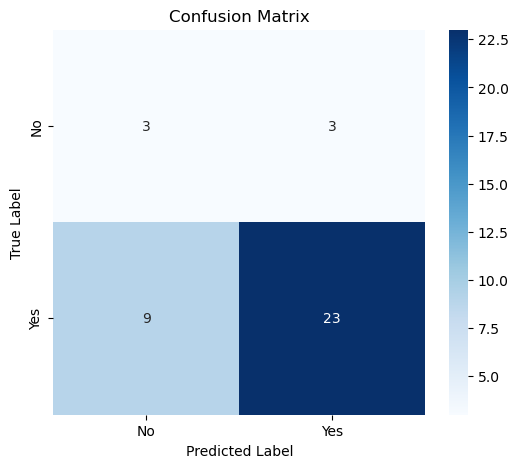

In [79]:
# Confusion matrix
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No', 'Yes'],
    yticklabels=['No', 'Yes']
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")

plt.show()

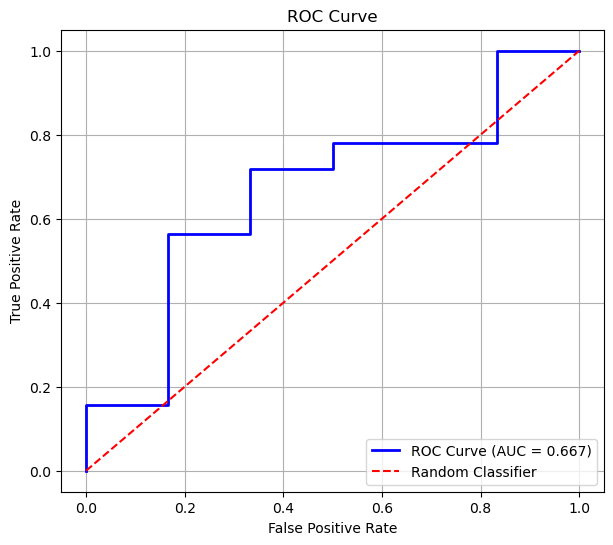

In [81]:
# ROC curve diagram
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# Compute ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob, pos_label='Yes')

# Compute AUC
roc_auc = auc(fpr, tpr)

# Plot ROC Curve
plt.figure(figsize=(7,6))

plt.plot(fpr, tpr,
         color='blue',
         linewidth=2,
         label=f'ROC Curve (AUC = {roc_auc:.3f})')

# Plot random classifier
plt.plot([0,1], [0,1],
         color='red',
         linestyle='--',
         label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.grid(True)

plt.show()

# SUPPORT VECTOR MACHINE

In [82]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score

# Train model
svm = SVC(probability=True, random_state=42)

svm.fit(X_train_scaled, y_train)

# Predictions
y_pred_svm = svm.predict(X_test_scaled)
y_prob_svm = svm.predict_proba(X_test_scaled)[:, 1]

# Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred_svm))
print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred_svm))
print("\nClassification Report")
print(classification_report(y_test, y_pred_svm))
print("\nROC-AUC:", roc_auc_score(y_test, y_prob_svm))

Accuracy: 0.8421052631578947

Confusion Matrix
[[ 0  6]
 [ 0 32]]

Classification Report
              precision    recall  f1-score   support

          No       0.00      0.00      0.00         6
         Yes       0.84      1.00      0.91        32

    accuracy                           0.84        38
   macro avg       0.42      0.50      0.46        38
weighted avg       0.71      0.84      0.77        38


ROC-AUC: 0.9270833333333334


C:\Users\CHINECHEREM\Apps\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\CHINECHEREM\Apps\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\CHINECHEREM\Apps\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


The Support Vector Machine (SVM) model achieved an accuracy of 84.21%. However, the confusion matrix revealed that the model classified every respondent as intending to migrate ("Yes"), resulting in a recall and precision of 0.00 for the "No" class. Although the overall accuracy appears high due to the imbalance in the dataset, the model failed to distinguish respondents who did not intend to migrate. Therefore, despite its higher accuracy, the SVM model was not considered suitable because it did not effectively classify both target classes.

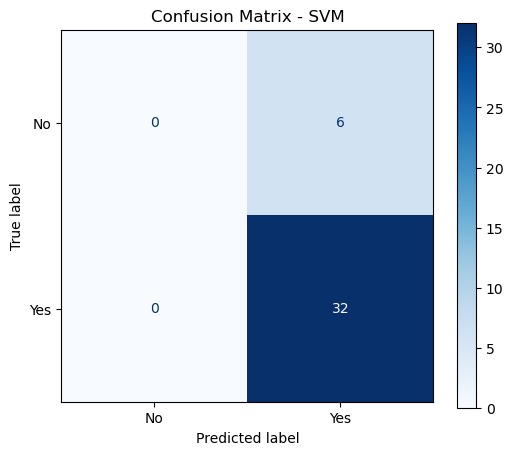

In [83]:
# Confusion matrix
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred_svm, labels=['No', 'Yes'])

# Plot confusion matrix
fig, ax = plt.subplots(figsize=(6,5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No', 'Yes']
)

disp.plot(cmap='Blues', ax=ax)

plt.title("Confusion Matrix - SVM")
plt.grid(False)
plt.show()

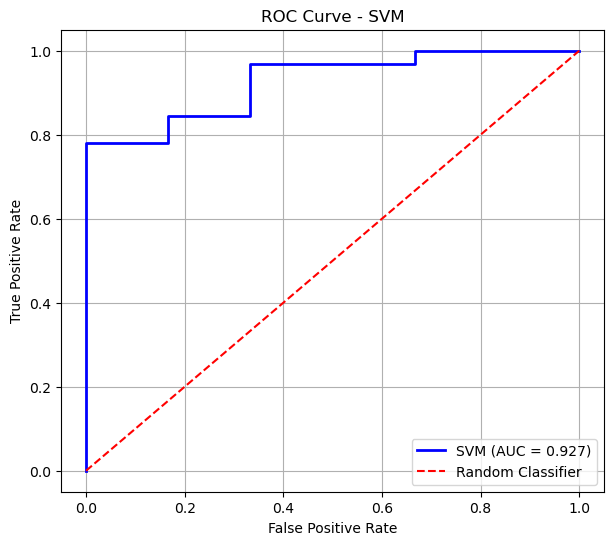

In [84]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# Compute ROC curve
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob_svm,
    pos_label='Yes'
)

# Compute AUC
roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure(figsize=(7,6))

plt.plot(
    fpr,
    tpr,
    color='blue',
    linewidth=2,
    label=f'SVM (AUC = {roc_auc:.3f})'
)

# Plot random classifier
plt.plot(
    [0,1],
    [0,1],
    color='red',
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - SVM')
plt.legend(loc='lower right')
plt.grid(True)

plt.show()

# Logistic Regression with L1 (Lasso) regularisation.

In [85]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score

# Train model
lasso = LogisticRegression(
    penalty='l1',
    solver='liblinear',
    random_state=42
)

lasso.fit(X_train_scaled, y_train)

# Predictions
y_pred_lasso = lasso.predict(X_test_scaled)
y_prob_lasso = lasso.predict_proba(X_test_scaled)[:, 1]

# Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred_lasso))
print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred_lasso))
print("\nClassification Report")
print(classification_report(y_test, y_pred_lasso))
print("\nROC-AUC:", roc_auc_score(y_test, y_prob_lasso))

Accuracy: 0.7894736842105263

Confusion Matrix
[[ 4  2]
 [ 6 26]]

Classification Report
              precision    recall  f1-score   support

          No       0.40      0.67      0.50         6
         Yes       0.93      0.81      0.87        32

    accuracy                           0.79        38
   macro avg       0.66      0.74      0.68        38
weighted avg       0.85      0.79      0.81        38


ROC-AUC: 0.734375


The L1-regularised Logistic Regression model achieved an accuracy of 78.95%, outperforming the standard Logistic Regression model. It demonstrated balanced performance across both classes, achieving a precision of 0.40, recall of 0.67, and F1-score of 0.50 for the minority "No" class, while maintaining strong performance for the majority "Yes" class (precision = 0.93, recall = 0.81, F1-score = 0.87). Compared with the standard Logistic Regression model, L1 regularisation improved the model's ability to correctly classify both respondents who intended to migrate and those who did not, suggesting that feature selection through regularisation enhanced predictive performance.

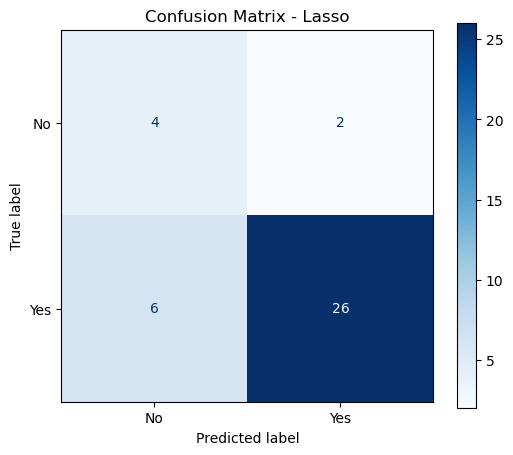

In [87]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred_lasso, labels=['No', 'Yes'])

# Plot confusion matrix
fig, ax = plt.subplots(figsize=(6,5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No', 'Yes']
)

disp.plot(cmap='Blues', ax=ax)

plt.title("Confusion Matrix - Lasso")
plt.grid(False)
plt.show()

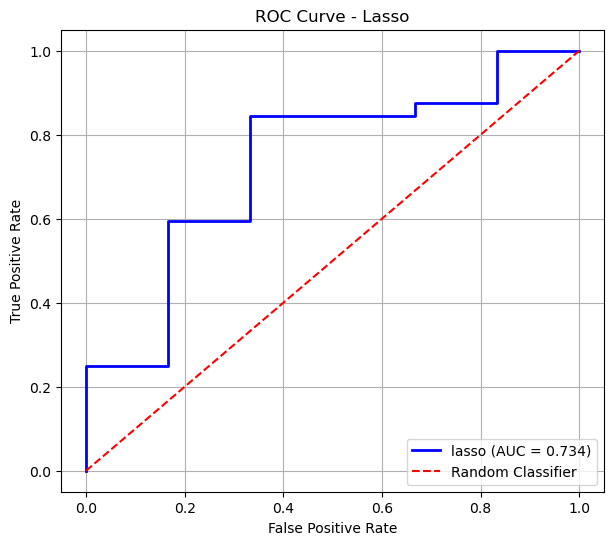

In [92]:
# Compute ROC curve
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob_lasso,
    pos_label='Yes'
)

# Compute AUC
roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure(figsize=(7,6))

plt.plot(
    fpr,
    tpr,
    color='blue',
    linewidth=2,
    label=f'lasso (AUC = {roc_auc:.3f})'
)

# Plot random classifier
plt.plot(
    [0,1],
    [0,1],
    color='red',
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Lasso')
plt.legend(loc='lower right')
plt.grid(True)

plt.show()

# RANDOM FOREST

In [89]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score

# Train model
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)

# Predictions
y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:, 1]

# Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred_rf))
print("\nClassification Report")
print(classification_report(y_test, y_pred_rf))
print("\nROC-AUC:", roc_auc_score(y_test, y_prob_rf))

Accuracy: 0.868421052631579

Confusion Matrix
[[ 2  4]
 [ 1 31]]

Classification Report
              precision    recall  f1-score   support

          No       0.67      0.33      0.44         6
         Yes       0.89      0.97      0.93        32

    accuracy                           0.87        38
   macro avg       0.78      0.65      0.68        38
weighted avg       0.85      0.87      0.85        38


ROC-AUC: 0.875


The Random Forest classifier achieved the highest overall performance among the evaluated models, with an accuracy of 86.84% and an ROC-AUC score of 0.875, indicating very good discriminative ability. The model demonstrated excellent performance in identifying respondents who intended to migrate, achieving a precision of 0.89, recall of 0.97, and an F1-score of 0.93 for the "Yes" class. Although its recall for the minority "No" class was lower (0.33), the model maintained the highest overall predictive performance and was therefore considered the strongest classifier among the models evaluated.

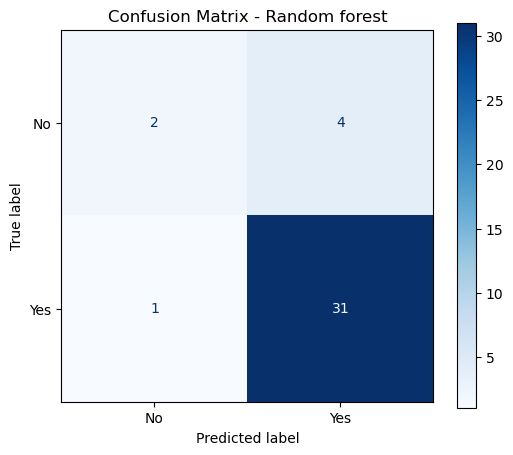

In [90]:
# Confusion matrix
# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred_rf, labels=['No', 'Yes'])

# Plot confusion matrix
fig, ax = plt.subplots(figsize=(6,5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No', 'Yes']
)

disp.plot(cmap='Blues', ax=ax)

plt.title("Confusion Matrix - Random forest")
plt.grid(False)
plt.show()

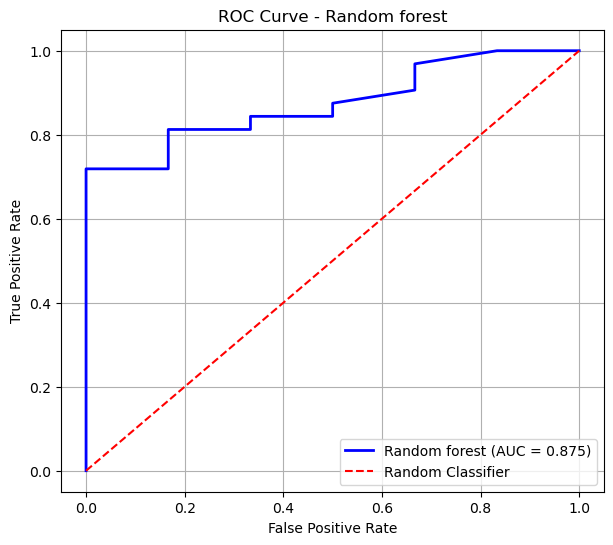

In [91]:
# Compute ROC curve
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob_rf,
    pos_label='Yes'
)

# Compute AUC
roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure(figsize=(7,6))

plt.plot(
    fpr,
    tpr,
    color='blue',
    linewidth=2,
    label=f'Random forest (AUC = {roc_auc:.3f})'
)

# Plot random classifier
plt.plot(
    [0,1],
    [0,1],
    color='red',
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Random forest')
plt.legend(loc='lower right')
plt.grid(True)

plt.show()

# Results comparison

| Metric          | Logistic | L1 Logistic |      SVM | Random Forest |
| --------------- | -------: | ----------: | -------: | ------------: |
| Accuracy        |   68.42% |      78.95% |  84.21%* |    **86.84%** |
| Precision (No)  |     0.25 |        0.40 |     0.00 |      **0.67** |
| Recall (No)     |     0.50 |    **0.67** |     0.00 |          0.33 |
| F1 (No)         |     0.33 |    **0.50** |     0.00 |          0.44 |
| Precision (Yes) |     0.88 |    **0.93** |     0.84 |          0.89 |
| Recall (Yes)    |     0.72 |        0.81 | **1.00** |      **0.97** |
| F1 (Yes)        |     0.79 |        0.87 |     0.91 |      **0.93** |
| ROC-AUC         |    0.667 |    0.734375 |  0.927083|     **0.875** |


Random Forest is currently the strongest overall model.

**Try out class balancing to handle class imbalance and retrain model**

# Logistic Regression with class weighting

In [93]:
from sklearn.linear_model import LogisticRegression

lr_weighted = LogisticRegression(
    class_weight='balanced',
    random_state=42,
    max_iter=1000
)

lr_weighted.fit(X_train, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [94]:
#Predictions
y_pred_lr = lr_weighted.predict(X_test)
y_prob_lr = lr_weighted.predict_proba(X_test)[:, 1]

In [95]:
# Evaluation
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("Accuracy:", accuracy_score(y_test, y_pred_lr))

print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred_lr))

print("\nClassification Report")
print(classification_report(y_test, y_pred_lr))

print("\nROC-AUC:",
      roc_auc_score(y_test, y_prob_lr))

Accuracy: 0.631578947368421

Confusion Matrix
[[ 5  1]
 [13 19]]

Classification Report
              precision    recall  f1-score   support

          No       0.28      0.83      0.42         6
         Yes       0.95      0.59      0.73        32

    accuracy                           0.63        38
   macro avg       0.61      0.71      0.57        38
weighted avg       0.84      0.63      0.68        38


ROC-AUC: 0.7395833333333333


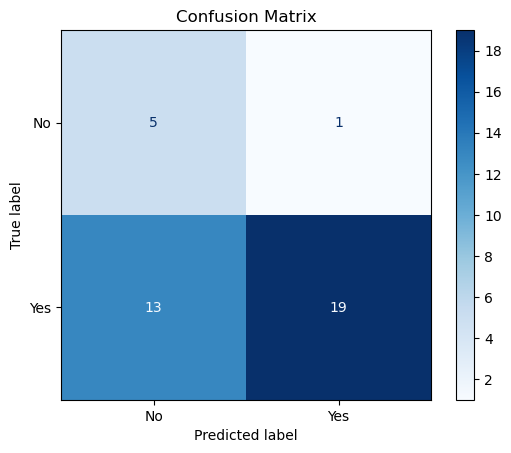

In [107]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    y_pred_lr,
    labels=["No","Yes"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No","Yes"]
)

disp.plot(cmap="Blues")

plt.title("Confusion Matrix")
plt.grid(False)
plt.show()

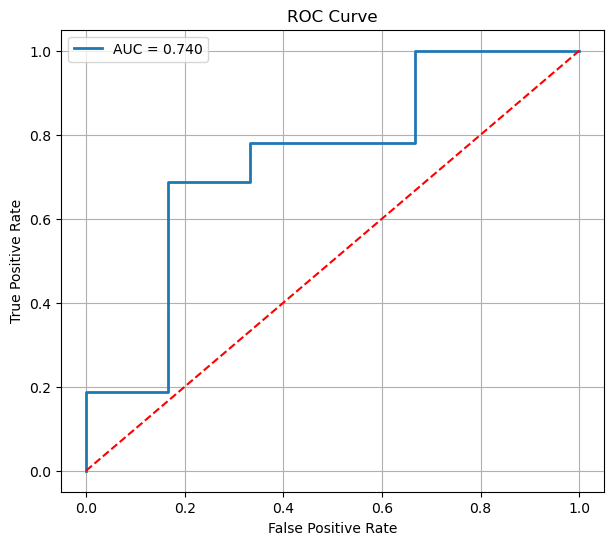

In [111]:
# ROC Curve
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

fpr, tpr, _ = roc_curve(
    y_test,
    y_prob_lr,
    pos_label="Yes"
)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7,6))
plt.plot(fpr, tpr, lw=2, label=f"AUC = {roc_auc:.3f}")
plt.plot([0,1],[0,1],'r--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(True)
plt.show()

# SVM with class weighting

In [96]:
from sklearn.svm import SVC

svm_weighted = SVC(
    probability=True,
    class_weight='balanced',
    random_state=42
)

svm_weighted.fit(X_train_scaled, y_train)

SVC(class_weight='balanced', probability=True, random_state=42)

In [97]:
# prediction
y_pred_svm = svm_weighted.predict(X_test_scaled)

y_prob_svm = svm_weighted.predict_proba(X_test_scaled)[:,1]

In [98]:
#Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred_svm))

print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred_svm))

print("\nClassification Report")
print(classification_report(y_test, y_pred_svm))

print("\nROC-AUC:",
      roc_auc_score(y_test, y_prob_svm))

Accuracy: 0.7894736842105263

Confusion Matrix
[[ 4  2]
 [ 6 26]]

Classification Report
              precision    recall  f1-score   support

          No       0.40      0.67      0.50         6
         Yes       0.93      0.81      0.87        32

    accuracy                           0.79        38
   macro avg       0.66      0.74      0.68        38
weighted avg       0.85      0.79      0.81        38


ROC-AUC: 0.8333333333333333


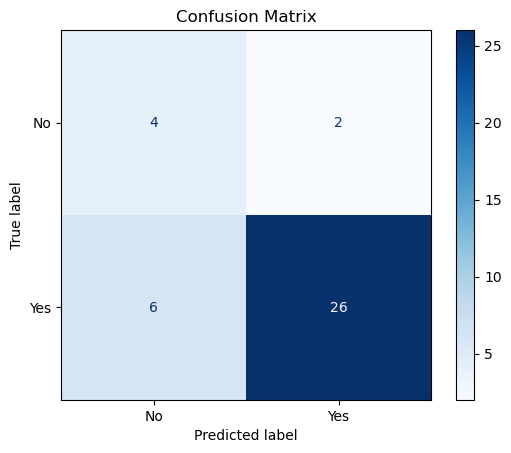

In [108]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    y_pred_svm,
    labels=["No","Yes"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No","Yes"]
)

disp.plot(cmap="Blues")

plt.title("Confusion Matrix")
plt.grid(False)
plt.show()

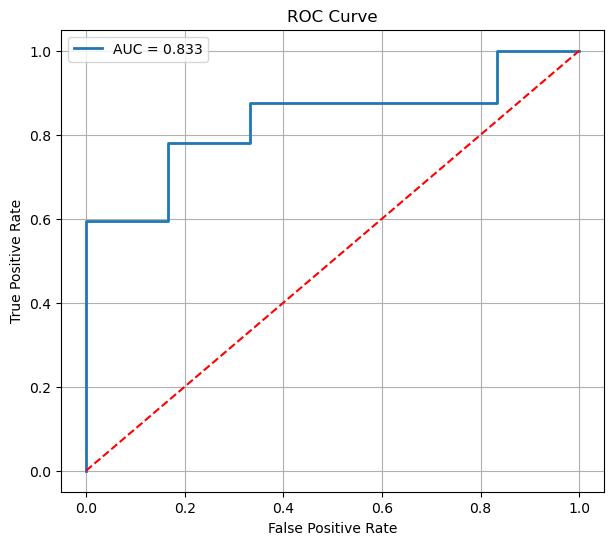

In [112]:
# ROC curve
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

fpr, tpr, _ = roc_curve(
    y_test,
    y_prob_svm,
    pos_label="Yes"
)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7,6))
plt.plot(fpr, tpr, lw=2, label=f"AUC = {roc_auc:.3f}")
plt.plot([0,1],[0,1],'r--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(True)
plt.show()

# L1 logistic regression with class weighting

In [99]:
from sklearn.linear_model import LogisticRegression

lasso_weighted = LogisticRegression(
    penalty='l1',
    solver='liblinear',      # Required for L1 penalty
    class_weight='balanced',
    random_state=42,
    max_iter=1000
)

lasso_weighted.fit(X_train, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, penalty='l1',
                   random_state=42, solver='liblinear')

In [101]:
# Predictions

y_pred_lasso = lasso_weighted.predict(X_test)

# Predicted probabilities
y_prob_lasso = lasso_weighted.predict_proba(X_test)[:, 1]

In [102]:
# Evaluation
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("Accuracy:", accuracy_score(y_test, y_pred_lasso))

print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred_lasso))

print("\nClassification Report")
print(classification_report(y_test, y_pred_lasso))

print("\nROC-AUC:", roc_auc_score(y_test, y_prob_lasso))

Accuracy: 0.6052631578947368

Confusion Matrix
[[ 5  1]
 [14 18]]

Classification Report
              precision    recall  f1-score   support

          No       0.26      0.83      0.40         6
         Yes       0.95      0.56      0.71        32

    accuracy                           0.61        38
   macro avg       0.61      0.70      0.55        38
weighted avg       0.84      0.61      0.66        38


ROC-AUC: 0.7552083333333333


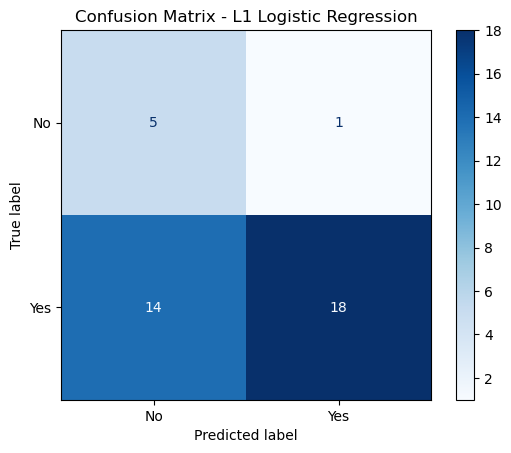

In [109]:
# Confusion matrix
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test,
    y_pred_lasso,
    labels=["No", "Yes"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No", "Yes"]
)

disp.plot(cmap="Blues")

plt.title("Confusion Matrix - L1 Logistic Regression")
plt.grid(False)
plt.show()

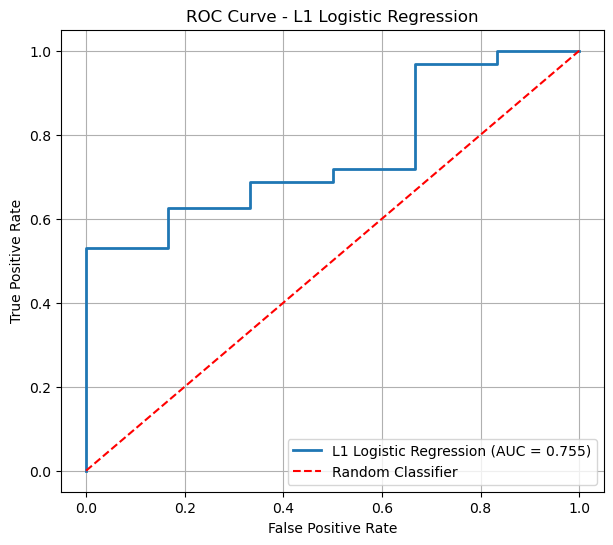

In [110]:
# ROC curve
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# Compute ROC curve
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob_lasso,
    pos_label="Yes"
)

# Compute AUC
roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure(figsize=(7,6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"L1 Logistic Regression (AUC = {roc_auc:.3f})"
)

# Random classifier
plt.plot(
    [0,1],
    [0,1],
    'r--',
    label='Random Classifier'
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - L1 Logistic Regression")
plt.legend(loc="lower right")
plt.grid(True)

plt.show()

# Random forest with class weighting

In [103]:
from sklearn.ensemble import RandomForestClassifier

rf_weighted = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42
)

rf_weighted.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', random_state=42)

In [104]:
# prediction
y_pred_rf = rf_weighted.predict(X_test)

y_prob_rf = rf_weighted.predict_proba(X_test)[:,1]

In [105]:
# Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred_rf))

print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred_rf))

print("\nClassification Report")
print(classification_report(y_test, y_pred_rf))

print("\nROC-AUC:",
      roc_auc_score(y_test, y_prob_rf))

Accuracy: 0.8947368421052632

Confusion Matrix
[[ 2  4]
 [ 0 32]]

Classification Report
              precision    recall  f1-score   support

          No       1.00      0.33      0.50         6
         Yes       0.89      1.00      0.94        32

    accuracy                           0.89        38
   macro avg       0.94      0.67      0.72        38
weighted avg       0.91      0.89      0.87        38


ROC-AUC: 0.875


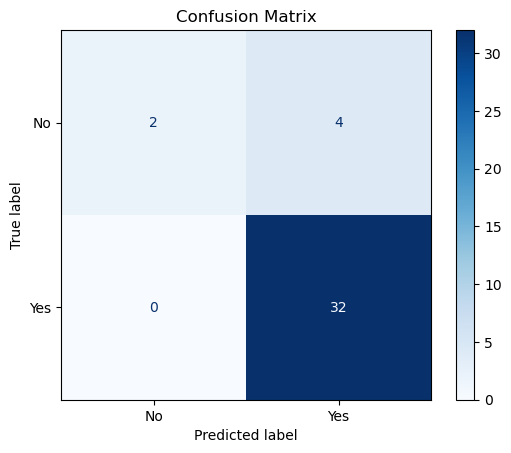

In [106]:
# Confusion matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=["No","Yes"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No","Yes"]
)

disp.plot(cmap="Blues")

plt.title("Confusion Matrix")
plt.grid(False)
plt.show()

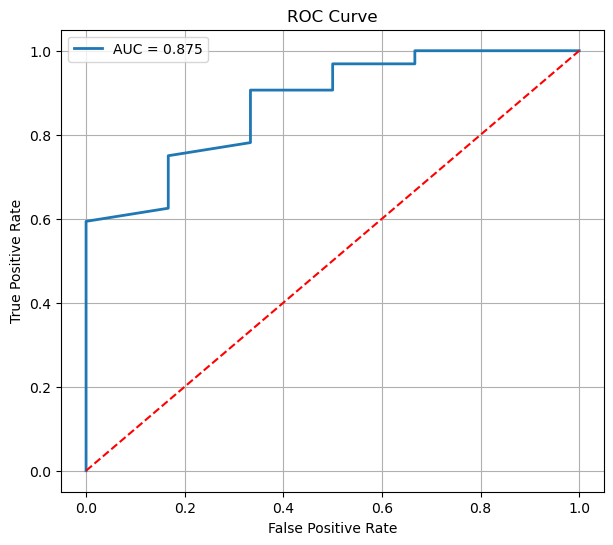

In [113]:
# ROC curve
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

fpr, tpr, _ = roc_curve(
    y_test,
    y_prob_rf,
    pos_label="Yes"
)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7,6))
plt.plot(fpr, tpr, lw=2, label=f"AUC = {roc_auc:.3f}")
plt.plot([0,1],[0,1],'r--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(True)
plt.show()

# Comparison of all weighted models

| Model                  |   Accuracy |   ROC-AUC | Recall (No) | F1-score (No) |
| ---------------------- | ---------: | --------: | ----------: | ------------: |
| Logistic Regression    |     63.16% |     0.740 |     **83%** |          0.42 |
| L1 Logistic Regression |     60.53% |     0.755 |     **83%** |          0.40 |
| SVM                    |     78.95% |     0.833 |         67% |      **0.50** |
| **Random Forest**      | **89.47%** | **0.875** |         33% |      **0.50** |


**Random Forest (Best Overall Performance)**

**Strengths:**

Highest accuracy (89.47%)

Highest ROC-AUC (0.875)

Perfect prediction of "Yes" cases

Strong weighted F1-score (0.87)

**Weakness:**

Lower detection of "No" cases.

**SVM (2nd Best)**

**Strengths:**

Good accuracy (78.95%)

Strong ROC-AUC (0.833)

Better balance between classes than Random Forest.

### Evaluation of Models After Applying Class Weighting

Class weighting was applied to address the imbalance in the target variable, where the number of respondents who had seriously considered leaving Nigeria ("Yes") was considerably higher than those who had not ("No"). Instead of modifying the dataset through oversampling or undersampling, class weighting adjusted the model training process by assigning greater importance to the minority class during prediction.

After applying class weighting, the performance of the models changed significantly. Logistic Regression and L1 Logistic Regression showed improved ability to identify the minority class ("No"), achieving a recall of 83%. However, this improvement resulted in reduced overall accuracy due to an increase in misclassification of the majority class.

The weighted SVM achieved a more balanced performance, with an accuracy of 78.95% and ROC-AUC of 0.833. It improved the identification of the minority class while maintaining good predictive performance for the majority class.

The weighted Random Forest model achieved the best overall predictive performance, obtaining the highest accuracy (89.47%) and ROC-AUC score (0.875). The model correctly classified all respondents who had considered leaving Nigeria ("Yes"). However, its ability to identify respondents who had not considered leaving Nigeria remained limited, with a recall of 33%, indicating that the model was still influenced by the majority class.

Overall, applying class weighting improved the models' sensitivity toward the minority class and provided a more reliable evaluation compared with the original imbalanced models. Based on the balance between predictive performance and discrimination ability, Random Forest with class weighting was selected as the best-performing model for predicting migration consideration among respondents.


# Feature importance

In [118]:
import pandas as pd
import matplotlib.pyplot as plt

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance.head(10))

                 Feature  Importance
6   career_goals_nigeria    0.073533
12       quality_of_life    0.072358
13  better_future_abroad    0.066132
11    personal_goal_hope    0.056756
18         factor_income    0.049185
14  emotional_attachment    0.044933
9        future_optimism    0.042062
4    income_satisfaction    0.038477
23   factor_quality_life    0.036113
8        public_services    0.034778


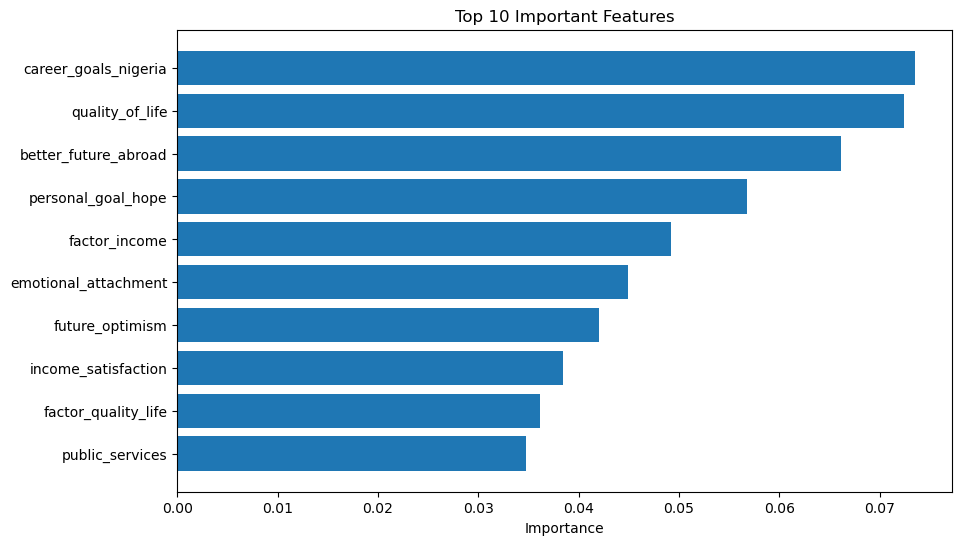

In [119]:
# Plot top 10 features
plt.figure(figsize=(10,6))

plt.barh(
    feature_importance["Feature"][:10],
    feature_importance["Importance"][:10]
)

plt.gca().invert_yaxis()

plt.title("Top 10 Important Features")

plt.xlabel("Importance")

plt.show()

The feature importance analysis shows that perceptions of career opportunities, quality of life, and future prospects in Nigeria are the strongest predictors of emigration intention. Economic factors such as higher income and satisfaction with public services also play a significant role, indicating that both personal aspirations and socioeconomic conditions strongly influence migration decisions.

# LIMITATIONS

1. Small sample size (188 respondents)


2. Class imbalance


3. Self-reported survey responses


4. Respondents may not represent the entire Nigerian population

# RECOMMENDATIONS

1. Collect more diverse data.

2. Employers should build clear career growth paths for young workers.

3. Universities should offer mentorship for local career goals.

4. Universities and NYSC should use the model to flag high-risk students early.

5. Government and NGOs should target funds using the model's risk scores.

6. Career centers should use predictions to give personalized advice.

7. Researchers should re-run the model to track if interventions work.
